# Aula 14 — Trabalho prático (entrega no Moodle)
## Quem vai ficar insatisfeito? Classificação dos pedidos da hamburgueria

**Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN**

Você vai aplicar o **fluxo de trabalho do scikit-learn** (Aula 14) ao dataset de delivery da Aula 12 (`dados/delivery_hamburgueria.csv`, 600 pedidos **fictícios**).

**Pergunta:** a partir das informações do pedido e da entrega, o modelo consegue identificar os clientes **insatisfeitos** (avaliação **≤ 3**)?

**Como entregar:** complete as células marcadas com `TODO`, **execute o notebook inteiro** (as saídas devem ficar visíveis) e envie o arquivo `.ipynb` na tarefa *Trabalho Prático — Aula 14* do Moodle. **Prazo: 23/11/2026, 23:59.**

### Critérios de avaliação (100 pontos)
| Etapa | Pontos |
|---|---|
| 1. Alvo e proporção das classes | 10 |
| 2. X, y e divisão treino/teste estratificada | 15 |
| 3. Baseline (`DummyClassifier`) | 10 |
| 4. Pipeline + regressão logística, com métricas no teste (acurácia, F1, ROC-AUC, matriz de confusão) | 25 |
| 5. Segundo modelo no mesmo pipeline | 10 |
| 6. Validação cruzada estratificada (5 folds) comparando os modelos | 20 |
| 7. Conclusão escrita | 10 |

> Use `random_state=42` em todos os lugares para que os resultados possam ser conferidos.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, classification_report)
SEMENTE = 42

df = pd.read_csv("dados/delivery_hamburgueria.csv")
df.head()

,pedido_id,data,dia_semana,turno,bairro,distancia_km,veiculo,chuva,itens,valor_pedido,taxa_entrega,tempo_entrega_min,avaliacao
0,1,2026-08-03,Seg,Almoço,Serra,6.6,Moto,Não,3,89.88,10.51,36,4
1,2,2026-08-03,Seg,Jantar,Serra,6.9,Moto,Não,3,73.78,10.41,39,3
2,3,2026-08-03,Seg,Almoço,Praia,7.7,Moto,Não,1,28.82,10.73,38,4
3,4,2026-08-03,Seg,Jantar,Serra,9.9,Moto,Não,2,66.48,12.61,46,4
4,5,2026-08-03,Seg,Almoço,Praia,6.3,Moto,Não,5,124.49,9.82,40,3


## Etapa 1 — Alvo e proporção das classes (10 pts)

Crie a coluna `insatisfeito` = 1 quando `avaliacao <= 3` e 0 caso contrário. Mostre a contagem e a proporção de cada classe. As classes estão balanceadas?

> ✅ Para conferir: **167 pedidos insatisfeitos (27,8%)**.

In [5]:

df["insatisfeito"] = (df["avaliacao"] <= 3).astype(int)

print("Contagem:")
print(df["insatisfeito"].value_counts())

print("\nProporção:")
print(df["insatisfeito"].value_counts(normalize=True))


print("\n",df.head())

# As classes não estão balanceadas: há mais pedidos satisfeitos do que insatisfeitos.

Contagem:
insatisfeito
0    433
1    167
Name: count, dtype: int64

Proporção:
insatisfeito
0    0.721667
1    0.278333
Name: proportion, dtype: float64

    pedido_id        data dia_semana   turno bairro  distancia_km veiculo  \
0          1  2026-08-03        Seg  Almoço  Serra           6.6    Moto   
1          2  2026-08-03        Seg  Jantar  Serra           6.9    Moto   
2          3  2026-08-03        Seg  Almoço  Praia           7.7    Moto   
3          4  2026-08-03        Seg  Jantar  Serra           9.9    Moto   
4          5  2026-08-03        Seg  Almoço  Praia           6.3    Moto   

  chuva  itens  valor_pedido  taxa_entrega  tempo_entrega_min  avaliacao  \
0   Não      3         89.88         10.51                 36          4   
1   Não      3         73.78         10.41                 39          3   
2   Não      1         28.82         10.73                 38          4   
3   Não      2         66.48         12.61                 46          4   
4   Não 

## Etapa 2 — X, y e divisão treino/teste (15 pts)

Use como atributos as colunas numéricas `distancia_km`, `itens`, `valor_pedido`, `taxa_entrega`, `tempo_entrega_min` e as categóricas `dia_semana`, `turno`, `bairro`, `veiculo`, `chuva`. **Não use `avaliacao`** (por quê? responda em um comentário). Separe 25% para teste, **estratificando** pelo alvo, com `random_state=42`.

> ✅ Treino com 450 pedidos e teste com 150, ambos com cerca de 28% de insatisfeitos.

In [6]:
numericas = ["distancia_km", "itens", "valor_pedido", "taxa_entrega", "tempo_entrega_min"]
categoricas = ["dia_semana", "turno", "bairro", "veiculo", "chuva"]

X, y = df.drop(columns=["insatisfeito"]), df["insatisfeito"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

### Por que não usar "avaliacao"?

Não usa avaliação porque é a variável que define o alvo (insatisfeito ou não). Se incluirmos a avaliação como atributo, o modelo terá acesso direto à informação que queremos prever, o que resultaria em um modelo que não generaliza bem para novos dados. Isso é conhecido como **data leakage**.

## Etapa 3 — Baseline (10 pts)

Treine um `DummyClassifier(strategy="most_frequent")` e calcule a acurácia e o F1 no teste. O que esse resultado mostra?

> ✅ Acurácia do baseline ≈ **0,72** e F1 = 0.

In [7]:
# TODO: dummy = DummyClassifier(...).fit(...)

dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
# imprima a acurácia e F1 no treino
y_pred_treino_dummy = dummy.predict(X_treino)
print("Dummy Classifier - Treino")
print("Acurácia:", accuracy_score(y_treino, y_pred_treino_dummy))
print("F1 Score:", f1_score(y_treino, y_pred_treino_dummy))

Dummy Classifier - Treino
Acurácia: 0.7222222222222222
F1 Score: 0.0


## Etapa 4 — Pipeline com regressão logística (25 pts)

Monte um `ColumnTransformer` (`StandardScaler` nas numéricas, `OneHotEncoder(handle_unknown="ignore")` nas categóricas) e um `Pipeline` com `LogisticRegression(max_iter=1000)`. Treine no treino e, **no teste**, mostre acurácia, F1, ROC-AUC (use `predict_proba`), a matriz de confusão e o `classification_report`.

> ✅ Seu modelo deve superar o baseline em F1 e ROC-AUC (referência: ROC-AUC entre 0,75 e 0,85).

Logistic Regression - Treino
Acurácia: 0.8022222222222222
F1 Score: 0.5700483091787439
ROC AUC: 0.8270276923076924
              precision    recall  f1-score   support

  Satisfeito       0.82      0.93      0.87       325
Insatisfeito       0.72      0.47      0.57       125

    accuracy                           0.80       450
   macro avg       0.77      0.70      0.72       450
weighted avg       0.79      0.80      0.79       450



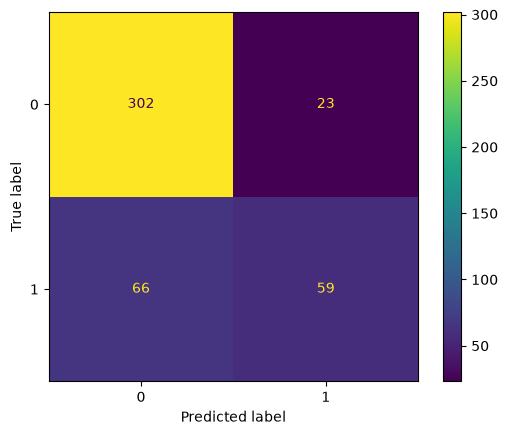

In [8]:
# preprocess = ColumnTransformer([...])
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(drop="first"), categoricas)
])
# modelo_log = Pipeline([("preprocess", preprocess), ("clf", LogisticRegression(max_iter=1000))])
modelo_log = Pipeline([("preprocess", preprocess), ("clf", LogisticRegression(max_iter=1000))])
# fit, predict, predict_proba
modelo_log.fit(X_treino, y_treino)
y_pred_treino_log = modelo_log.predict(X_treino)
y_pred_proba_treino_log = modelo_log.predict_proba(X_treino)
# métricas + ConfusionMatrixDisplay.from_predictions(...) + classification_report(...)
print("Logistic Regression - Treino")
print("Acurácia:", accuracy_score(y_treino, y_pred_treino_log))
print("F1 Score:", f1_score(y_treino, y_pred_treino_log))
print("ROC AUC:", roc_auc_score(y_treino, y_pred_proba_treino_log[:, 1]))
ConfusionMatrixDisplay.from_predictions(y_treino, y_pred_treino_log)
print(classification_report(y_treino, y_pred_treino_log, target_names=["Satisfeito", "Insatisfeito"]))

## Etapa 5 — Segundo modelo (10 pts)

Troque apenas o classificador do pipeline por uma `DecisionTreeClassifier(max_depth=4, random_state=42)` **ou** uma `RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)` e calcule as mesmas métricas no teste.

> ✅ Compare com a regressão logística: qual se saiu melhor em cada métrica?

In [11]:

modelo_2 = Pipeline([("preprocess", preprocess), ("clf", LogisticRegression(max_iter=1000))])
modelo_2.fit(X_treino, y_treino)

y_pred_2 = modelo_2.predict(X_teste)
print(classification_report(y_teste, y_pred_2, target_names=["Satisfeito", "Insatisfeito"]))

              precision    recall  f1-score   support

  Satisfeito       0.79      0.86      0.82       108
Insatisfeito       0.53      0.40      0.46        42

    accuracy                           0.73       150
   macro avg       0.66      0.63      0.64       150
weighted avg       0.72      0.73      0.72       150



## Etapa 6 — Validação cruzada (20 pts)

Com `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` e `cross_validate` **no conjunto de treino**, compare baseline, regressão logística e o seu segundo modelo usando `scoring=["accuracy", "f1", "roc_auc"]`. Monte uma tabela com a **média** e o **desvio-padrão** de cada métrica.

> ✅ Uma tabela com 3 linhas (modelos) e as métricas em média ± desvio-padrão.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

r = cross_validate(modelo_2, X_treino, y_treino, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1'])

df = pd.DataFrame(r)
df = df.mean()
df['std'] = df.std()

print(df)

fit_time          0.010957
score_time        0.010697
test_accuracy     0.793333
test_precision    0.708980
test_recall       0.464000
test_f1           0.552962
std               0.339786
dtype: float64


## Etapa 7 — Conclusão (10 pts)
Em uma célula Markdown (5 a 8 linhas), responda:
1. Qual modelo você escolheria e com base em qual métrica? Por que **não** usar só a acurácia?
2. O que a matriz de confusão diz sobre os erros do modelo (falsos positivos × falsos negativos)?
3. A variável `tempo_entrega_min` só é conhecida **depois** da entrega. Se a empresa quisesse prever a insatisfação **no momento do pedido**, o que mudaria no seu modelo?

1. Eu escolheria o modelo que apresentar o maior F1 na validação cruzada, equilibrando a identificação de insatisfeitos e a quantidade de falsos positivos.
Não usaria apenas a acurácia porque a classe insatisfeita é minoritária, e prever sempre “satisfeito” já produz uma acurácia razoável, mas F1 igual a zero.

2. Na matriz de confusão, falsos negativos são clientes insatisfeitos classificados como satisfeitos; falsos positivos são clientes satisfeitos classificados como insatisfeitos.
Para a empresa, os falsos negativos podem ser mais prejudiciais, pois deixam de permitir uma ação de recuperação com o cliente.

3. Para prever no momento do pedido, eu removeria `tempo_entrega_min` e qualquer outra variável conhecida somente após a entrega.
O pipeline seria treinado novamente apenas com informações disponíveis no instante do pedido, e suas métricas seriam reavaliadas.

**TODO — escreva aqui a sua conclusão.**